# 1. Install the required libraries

In [1]:

# Install all required libraries in Colab.
!pip install -q ultralytics pyyaml pandas matplotlib pillow opencv-python psutil


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.8 MB/s eta 0:00:00


#Step 2 — Mount Google Drive and check hardware 2.Connect Google Drive and check GPU

In [2]:

# Mount Google Drive so the notebook can read the dataset and save trained models.
from google.colab import drive
import torch, psutil

drive.mount('/content/drive')

print('PyTorch version:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name:', torch.cuda.get_device_name(0))
    total_gpu_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print('Total GPU memory:', round(total_gpu_gb, 2), 'GB')
print('Available RAM:', round(psutil.virtual_memory().available / (1024**3), 2), 'GB')


Mounted at /content/drive
PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4
Total GPU memory: 14.56 GB
Available RAM: 10.87 GB


# Step 3 — Locate the original Kaggle dataset

In [4]:

# This is your already-extracted dataset folder in Google Drive.
from pathlib import Path
from collections import Counter

BASE = Path('/content/drive/MyDrive/Component02_Research')
ORIGINAL_DATASET = BASE / 'licence-plates'

assert ORIGINAL_DATASET.exists(), f'Original dataset not found: {ORIGINAL_DATASET}'
print('Original dataset found at:', ORIGINAL_DATASET)

# Show the first few files and extension counts.
for path in sorted(ORIGINAL_DATASET.rglob('*'))[:40]:
    print(path.relative_to(ORIGINAL_DATASET))

extensions = Counter(
    p.suffix.lower() for p in ORIGINAL_DATASET.rglob('*') if p.is_file()
)
print('File extension counts:', extensions)


Original dataset found at: /content/drive/MyDrive/Component02_Research/licence-plates
convert.py
train
train/annotations
train/annotations/Cars0.xml
train/annotations/Cars1.xml
train/annotations/Cars10.xml
train/annotations/Cars100.xml
train/annotations/Cars101.xml
train/annotations/Cars102.xml
train/annotations/Cars103.xml
train/annotations/Cars104.xml
train/annotations/Cars105.xml
train/annotations/Cars106.xml
train/annotations/Cars107.xml
train/annotations/Cars108.xml
train/annotations/Cars109.xml
train/annotations/Cars11.xml
train/annotations/Cars110.xml
train/annotations/Cars111.xml
train/annotations/Cars112.xml
train/annotations/Cars113.xml
train/annotations/Cars114.xml
train/annotations/Cars115.xml
train/annotations/Cars116.xml
train/annotations/Cars117.xml
train/annotations/Cars118.xml
train/annotations/Cars119.xml
train/annotations/Cars12.xml
train/annotations/Cars120.xml
train/annotations/Cars121.xml
train/annotations/Cars122.xml
train/annotations/Cars123.xml
train/annotation

# Step 4 — Prepare a clean YOLO dataset (train/val/test) and convert XML annotations

In [5]:

# This cell:
# 1) copies the original images,
# 2) creates a fixed train/val/test split,
# 3) converts Pascal VOC XML annotations to YOLO TXT labels,
# 4) keeps the original dataset unchanged.

import shutil
import random
import xml.etree.ElementTree as ET
from PIL import Image

random.seed(42)

PREPARED = BASE / 'prepared_yolo'
TRAIN_DIR = PREPARED / 'train'
VAL_DIR = PREPARED / 'val'
TEST_DIR = PREPARED / 'test'

for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    (split_dir / 'images').mkdir(parents=True, exist_ok=True)
    (split_dir / 'labels').mkdir(parents=True, exist_ok=True)

# Source folders from the original dataset
orig_train_images = sorted((ORIGINAL_DATASET / 'train' / 'images').glob('*.png'))
orig_val_images = sorted((ORIGINAL_DATASET / 'val' / 'images').glob('*.png'))

print('Original train images:', len(orig_train_images))
print('Original val images:', len(orig_val_images))

# We keep the original val images as validation.
# We create a held-out test set by moving 40 images from original train.
all_train = orig_train_images.copy()
random.shuffle(all_train)

test_images = all_train[:40]
new_train_images = all_train[40:]
val_images = orig_val_images

print('New train size:', len(new_train_images))
print('Val size:', len(val_images))
print('Test size:', len(test_images))

def convert_xml_to_yolo(image_path, xml_path, txt_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    with Image.open(image_path) as img:
        width, height = img.size

    lines = []
    for obj in root.findall('object'):
        class_name = obj.findtext('name', '').strip()
        if class_name != 'licence':
            continue

        box = obj.find('bndbox')
        if box is None:
            continue

        xmin = float(box.findtext('xmin'))
        ymin = float(box.findtext('ymin'))
        xmax = float(box.findtext('xmax'))
        ymax = float(box.findtext('ymax'))

        # Clip the box to image boundaries
        xmin = max(0, min(width, xmin))
        xmax = max(0, min(width, xmax))
        ymin = max(0, min(height, ymin))
        ymax = max(0, min(height, ymax))

        if xmax <= xmin or ymax <= ymin:
            continue

        x_center = ((xmin + xmax) / 2) / width
        y_center = ((ymin + ymax) / 2) / height
        box_width = (xmax - xmin) / width
        box_height = (ymax - ymin) / height

        lines.append(
            f"0 {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}"
        )

      # Save each YOLO annotation on a separate line
    txt_path.write_text("\n".join(lines))
    return len(lines)

def process_split(image_list, destination_split, source_annotation_root):
    image_out = destination_split / 'images'
    label_out = destination_split / 'labels'

    image_count = 0
    label_count = 0
    object_count = 0

    for image_path in image_list:
        xml_path = source_annotation_root / f'{image_path.stem}.xml'
        txt_path = label_out / f'{image_path.stem}.txt'

        shutil.copy2(image_path, image_out / image_path.name)
        image_count += 1

        if not xml_path.exists():
            raise FileNotFoundError(f'Missing XML: {xml_path}')

        objects = convert_xml_to_yolo(image_path, xml_path, txt_path)
        label_count += 1
        object_count += objects

    return image_count, label_count, object_count

# Reset prepared folders if re-running
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for sub in ['images', 'labels']:
        folder = split_dir / sub
        for file in folder.glob('*'):
            file.unlink()

train_counts = process_split(new_train_images, TRAIN_DIR, ORIGINAL_DATASET / 'train' / 'annotations')
val_counts = process_split(val_images, VAL_DIR, ORIGINAL_DATASET / 'val' / 'annotations')
test_counts = process_split(test_images, TEST_DIR, ORIGINAL_DATASET / 'train' / 'annotations')

print('\nPrepared dataset created successfully!')
print('Train:', train_counts)
print('Val  :', val_counts)
print('Test :', test_counts)


Original train images: 400
Original val images: 33
New train size: 360
Val size: 33
Test size: 40

Prepared dataset created successfully!
Train: (360, 360, 386)
Val  : (33, 33, 35)
Test : (40, 40, 50)


# Step 5 — Create data.yaml and verify dataset counts

In [6]:

# Create a YOLO data.yaml inside the prepared dataset.
import yaml

yaml_config = {
    'path': str(PREPARED),
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'names': {0: 'licence'}
}

yaml_path = PREPARED / 'data.yaml'
with open(yaml_path, 'w') as f:
    yaml.safe_dump(yaml_config, f, sort_keys=False)

print(yaml_path.read_text())

# Verify prepared dataset counts
for split in ['train', 'val', 'test']:
    images = list((PREPARED / split / 'images').glob('*.png'))
    labels = list((PREPARED / split / 'labels').glob('*.txt'))
    obj_count = 0
    for label in labels:
        obj_count += len([ln for ln in label.read_text().splitlines() if ln.strip()])
    print(f'{split:5}: {len(images)} images, {len(labels)} labels, {obj_count} objects')


path: /content/drive/MyDrive/Component02_Research/prepared_yolo
train: train/images
val: val/images
test: test/images
names:
  0: licence

train: 360 images, 360 labels, 386 objects
val  : 33 images, 33 labels, 35 objects
test : 40 images, 40 labels, 50 objects


# Step 6 — Visualize a few bounding boxes before training

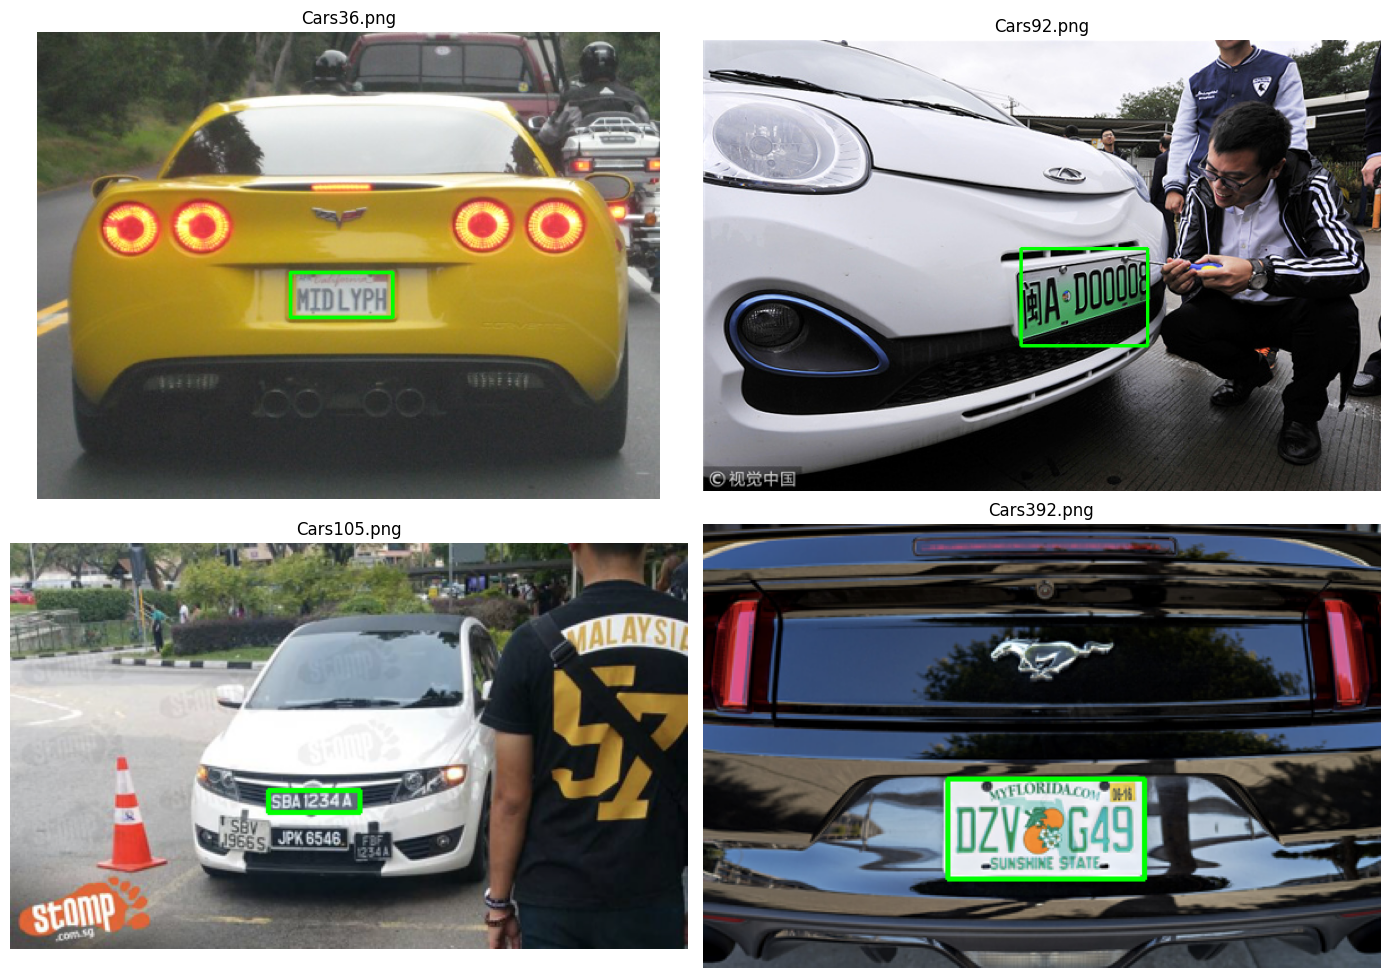

In [7]:

# This step confirms that green boxes actually surround the number plates.
import cv2
import random
import matplotlib.pyplot as plt

sample_images = random.sample(list((PREPARED / 'train' / 'images').glob('*.png')), 4)

plt.figure(figsize=(14, 10))
for i, image_path in enumerate(sample_images, start=1):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]

    label_path = PREPARED / 'train' / 'labels' / f'{image_path.stem}.txt'
    for line in label_path.read_text().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())
        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    plt.subplot(2, 2, i)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis('off')

plt.tight_layout()
plt.show()


# Step 7 — Copy the prepared dataset to Colab local storage (recommended for stable training)

In [8]:

# Training from /content is usually more stable and faster than training directly from Google Drive.
import shutil

LOCAL_PREPARED = Path('/content/prepared_yolo')

if LOCAL_PREPARED.exists():
    shutil.rmtree(LOCAL_PREPARED)

shutil.copytree(PREPARED, LOCAL_PREPARED)
print('Copied prepared dataset to:', LOCAL_PREPARED)

local_yaml = LOCAL_PREPARED / 'data.yaml'
print(local_yaml.read_text())


Copied prepared dataset to: /content/prepared_yolo
path: /content/drive/MyDrive/Component02_Research/prepared_yolo
train: train/images
val: val/images
test: test/images
names:
  0: licence



# Step 8 — Define common training settings (same settings for all five models)

In [9]:

# Keep the same settings for all five models to make the comparison fair.
from ultralytics import YOLO
import gc

EXPERIMENTS = BASE / 'experiments_lowmem_clean'
EXPERIMENTS.mkdir(parents=True, exist_ok=True)

MODELS = {
    'YOLO11n': 'yolo11n.pt',
    'YOLO11s': 'yolo11s.pt',
    'YOLO11m': 'yolo11m.pt',
    'YOLOv8n': 'yolov8n.pt',
    'YOLOv8s': 'yolov8s.pt',
}

TRAIN_ARGS = dict(
    data=str(LOCAL_PREPARED / 'data.yaml'),
    epochs=30,        # lower than 50 to reduce Colab crash risk
    imgsz=416,        # smaller image size = lower memory usage
    batch=2,          # small batch = safer on free Colab GPUs
    workers=0,        # reduces dataloader overhead
    cache=False,      # do not cache images in RAM
    optimizer='AdamW',
    lr0=0.001,
    patience=10,
    seed=42,
    amp=True,
    project=str(EXPERIMENTS),
    save=True,
    save_period=5,
    plots=True,
)

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Training device:', DEVICE)
print('Experiments folder:', EXPERIMENTS)
print('Models to compare:', list(MODELS.keys()))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Training device: 0
Experiments folder: /content/drive/MyDrive/Component02_Research/experiments_lowmem_clean
Models to compare: ['YOLO11n', 'YOLO11s', 'YOLO11m', 'YOLOv8n', 'YOLOv8s']


In [14]:
# ==============================================
# CHECK ALL FIVE TRAINED MODEL CHECKPOINTS
# ==============================================

from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Component02_Research"
)

EXPERIMENTS = BASE / "experiments_lowmem_clean"

MODELS = {
    "YOLO11n": "yolo11n.pt",
    "YOLO11s": "yolo11s.pt",
    "YOLO11m": "yolo11m.pt",
    "YOLOv8n": "yolov8n.pt",
    "YOLOv8s": "yolov8s.pt"
}

for name in MODELS:

    folder = EXPERIMENTS / name / "weights"

    best = folder / "best.pt"
    last = folder / "last.pt"

    print(f"\n{name}")
    print("Best checkpoint:", best.exists())
    print("Last checkpoint:", last.exists())


YOLO11n
Best checkpoint: True
Last checkpoint: True

YOLO11s
Best checkpoint: True
Last checkpoint: True

YOLO11m
Best checkpoint: True
Last checkpoint: True

YOLOv8n
Best checkpoint: True
Last checkpoint: True

YOLOv8s
Best checkpoint: True
Last checkpoint: True


# Step 9 — Train only the first model (YOLO11n)

In [ ]:

# IMPORTANT: Run this first.
# If this model trains successfully, then continue to the remaining four models.

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model = YOLO(MODELS['YOLO11n'])
results = model.train(
    device=DEVICE,
    name='YOLO11n',
    exist_ok=True,
    **TRAIN_ARGS,
)
print('YOLO11n training completed!')


# Step 10 — Check the first model checkpoint and graph

best.pt exists: True
best.pt path: /content/drive/MyDrive/Component02_Research/experiments_lowmem_clean/YOLO11n/weights/best.pt
results.png exists: True


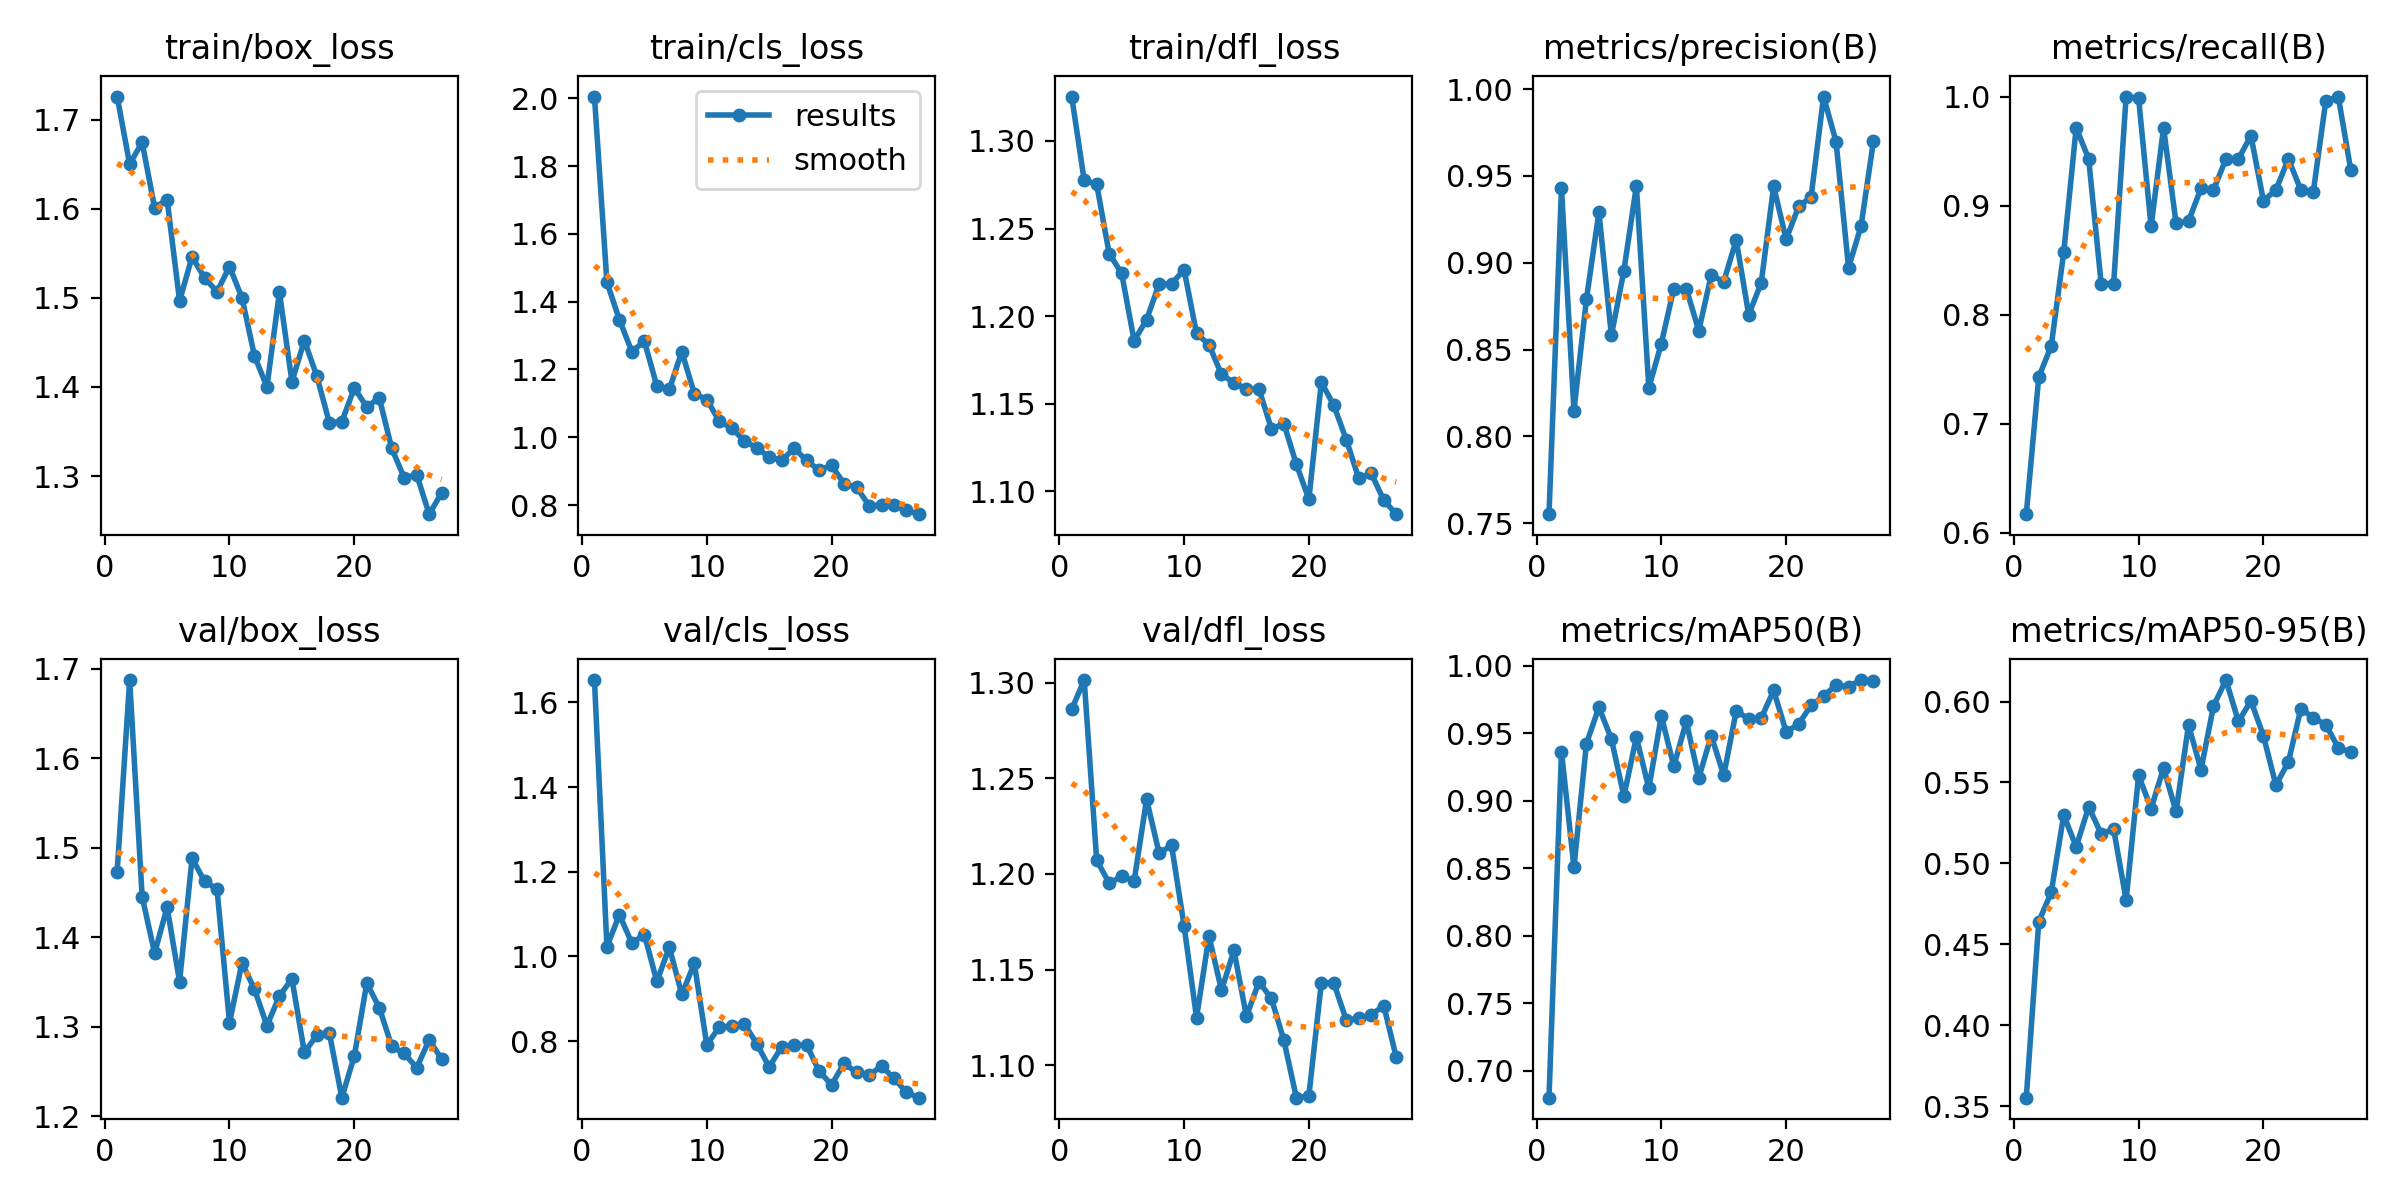

In [ ]:

# Verify that best.pt exists and preview the training graph.
from IPython.display import Image as IPyImage, display

best_model_path = EXPERIMENTS / 'YOLO11n' / 'weights' / 'best.pt'
results_image = EXPERIMENTS / 'YOLO11n' / 'results.png'

print('best.pt exists:', best_model_path.exists())
print('best.pt path:', best_model_path)
print('results.png exists:', results_image.exists())

if results_image.exists():
    display(IPyImage(filename=str(results_image)))


# Step 11 — Optional: Resume the first model if Colab disconnects

In [ ]:

# Only use this if training stopped and last.pt already exists.
last_checkpoint = EXPERIMENTS / 'YOLO11n' / 'weights' / 'last.pt'

if last_checkpoint.exists():
    print('Resuming from:', last_checkpoint)
    model = YOLO(str(last_checkpoint))
    model.train(resume=True)
else:
    print('No last.pt checkpoint found. Start a new run instead.')


# Step 12 — Train the remaining four models (run only after YOLO11n succeeds)

In [11]:

# This trains the remaining four models one by one.
# Skip YOLO11n because it was already trained above.

for model_name, weights in MODELS.items():
    if model_name == 'YOLOv8n':
        continue

    print("\n" + '=' * 60)
    print('Training', model_name)
    print('=' * 60)

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    model = YOLO(weights)
    model.train(
        device=DEVICE,
        name=model_name,
        exist_ok=True,
        **TRAIN_ARGS,
    )

print('All remaining models finished!')



Training YOLO11n
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/prepared_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n, nbs=64, nms=None, opset=None, 

In [13]:
# STEP 12 — Train ONE remaining model, not a four-model loop.
# Start with YOLOv8n, then change the name to YOLOv8s in a later session.
# If last.pt exists from a crash, resume the SAME run rather than restarting.

import gc
import torch
from ultralytics import YOLO

model_name = 'YOLOv8n'  # Later change only this to 'YOLOv8s'
weights_dir = EXPERIMENTS / model_name / 'weights'
last_path = weights_dir / 'last.pt'
best_path = weights_dir / 'best.pt'

assert (LOCAL_PREPARED / 'data.yaml').exists(), 'Run Step 7 first.'
assert DEVICE != 'cpu', 'No GPU available; wait for a GPU Colab session before training.'

gc.collect()
torch.cuda.empty_cache()

print('Selected model:', model_name)
print('Existing best.pt:', best_path.exists())
print('Existing last.pt:', last_path.exists())

# To avoid accidentally restarting a partially trained model, we resume whenever last.pt exists.
# If this model already completed, DO NOT run this cell again.
if last_path.exists():
    print('Resuming existing training from:', last_path)
    model = YOLO(str(last_path))
    model.train(resume=True)
else:
    print('Starting a NEW training run:', model_name)
    model = YOLO(MODELS[model_name])
    model.train(device=DEVICE, name=model_name, exist_ok=True, **TRAIN_ARGS)

print('Training call finished for:', model_name)


Selected model: YOLOv8n
Existing best.pt: False
Existing last.pt: False
Starting a NEW training run: YOLOv8n
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/prepared_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt

# Step 13 — Compare the five trained models on the validation set

In [15]:

import pandas as pd

comparison = []

for model_name in MODELS.keys():
    weights_path = EXPERIMENTS / model_name / 'weights' / 'best.pt'

    if not weights_path.exists():
        print('Missing:', weights_path)
        continue

    print('Validating:', model_name)
    model = YOLO(str(weights_path))
    metrics = model.val(
        data=str(LOCAL_PREPARED / 'data.yaml'),
        split='val',
        imgsz=416,
        batch=2,
        device=DEVICE,
        workers=0,
        verbose=False,
    )

    comparison.append({
        'Model': model_name,
        'Precision': float(metrics.box.mp),
        'Recall': float(metrics.box.mr),
        'mAP50': float(metrics.box.map50),
        'mAP50-95': float(metrics.box.map),
        'Size_MB': round(weights_path.stat().st_size / (1024 ** 2), 2),
    })

comparison_df = pd.DataFrame(comparison).sort_values(by='mAP50-95', ascending=False)
comparison_df


Validating: YOLO11n
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 292.2±61.3 MB/s, size: 575.7 KB)
val: Scanning /content/drive/MyDrive/Component02_Research/prepared_yolo/val/labels.cache... 33 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 33/33 7.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 13.8it/s 1.2s
                   all         33         35      0.872      0.971      0.967      0.616
Speed: 0.2ms preprocess, 14.8ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/runs/detect/val
Validating: YOLO11s
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0

,Model,Precision,Recall,mAP50,mAP50-95,Size_MB
2,YOLO11m,0.934438,1.000000,0.990533,0.647129,38.60
4,YOLOv8s,0.967527,1.000000,0.990278,0.637820,21.44
1,YOLO11s,0.919088,1.000000,0.979137,0.637590,18.25
3,YOLOv8n,0.963627,0.971429,0.988841,0.619822,6.17
0,YOLO11n,0.872369,0.971429,0.966553,0.616407,5.21


# Step 14 — Save the comparison table and select the best model

In [16]:

comparison_csv = BASE / 'model_comparison_validation.csv'
comparison_df.to_csv(comparison_csv, index=False)
print('Saved comparison table to:', comparison_csv)

best_model_name = comparison_df.iloc[0]['Model']
best_weights = EXPERIMENTS / best_model_name / 'weights' / 'best.pt'
print('Best model based on validation mAP50-95:', best_model_name)
print('Best model path:', best_weights)


Saved comparison table to: /content/drive/MyDrive/Component02_Research/model_comparison_validation.csv
Best model based on validation mAP50-95: YOLO11m
Best model path: /content/drive/MyDrive/Component02_Research/experiments_lowmem_clean/YOLO11m/weights/best.pt


# Step 15 — Evaluate the selected best model on the held-out test set

In [17]:

winner = YOLO(str(best_weights))

test_metrics = winner.val(
    data=str(LOCAL_PREPARED / 'data.yaml'),
    split='test',
    imgsz=416,
    batch=2,
    device=DEVICE,
    workers=0,
)

print('Test Precision :', float(test_metrics.box.mp))
print('Test Recall    :', float(test_metrics.box.mr))
print('Test mAP50     :', float(test_metrics.box.map50))
print('Test mAP50-95  :', float(test_metrics.box.map))


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 308.0±41.6 MB/s, size: 593.4 KB)
val: Scanning /content/drive/MyDrive/Component02_Research/prepared_yolo/test/labels... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 228.4it/s 0.2s
val: New cache created: /content/drive/MyDrive/Component02_Research/prepared_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 13.4it/s 1.5s
                   all         40         50      0.817       0.82      0.865      0.462
Speed: 0.2ms preprocess, 15.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/detect/val-6
Test Precision : 0.8173675801246177
Test Recall    : 0.82
Test mAP50     : 0.864902005498728
Test mAP50-95  : 0.46156874386359636


# Step 16 — Visualize predictions from the selected best model

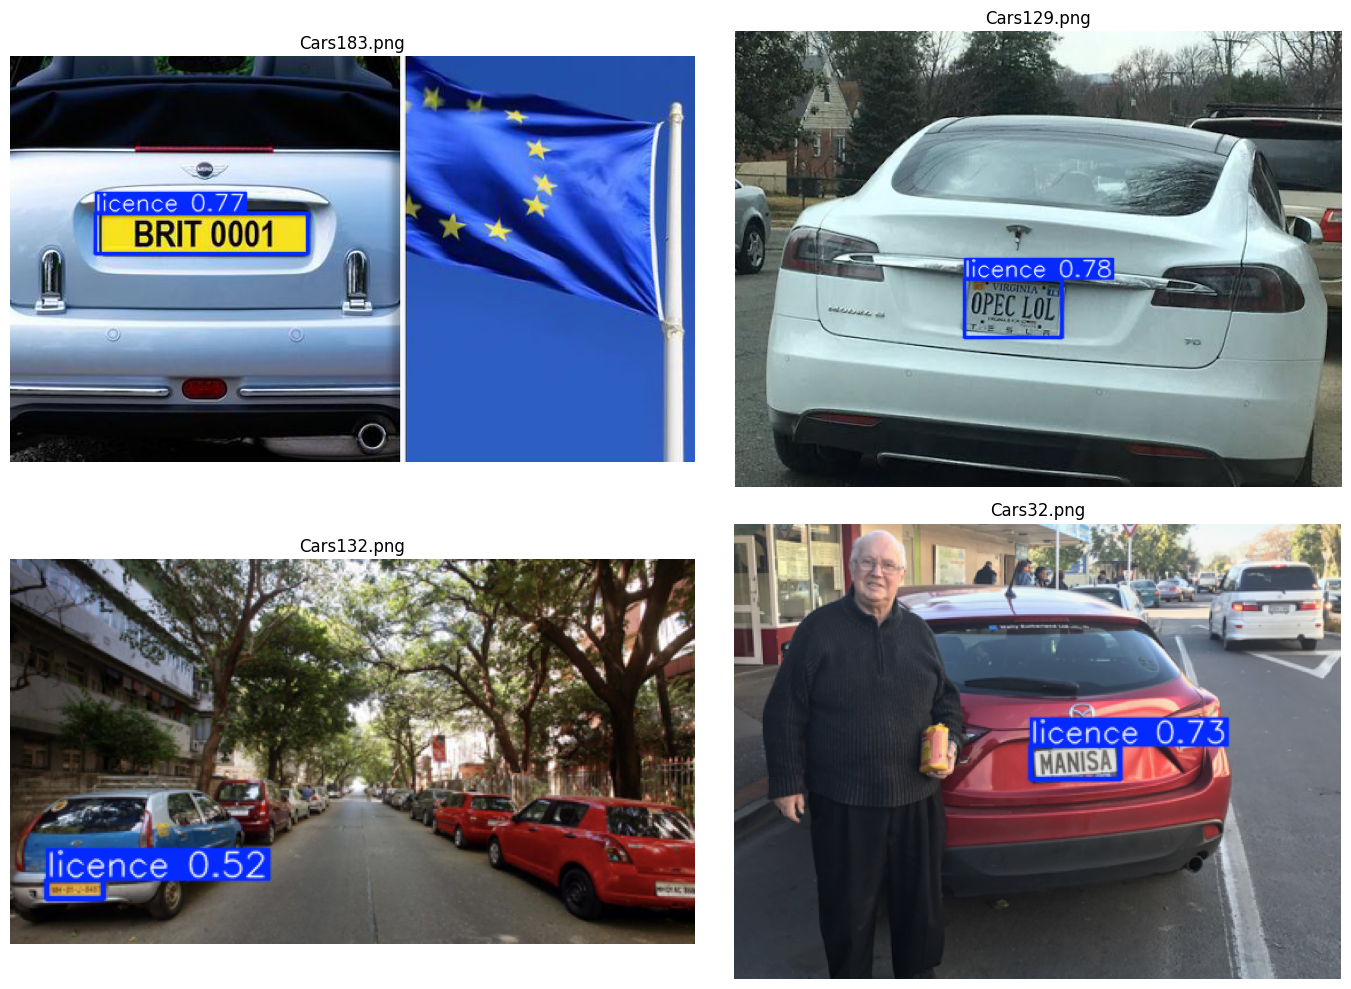

In [18]:

# Run the selected model on a few unseen test images and display predictions.
from PIL import Image
import matplotlib.pyplot as plt
import random

sample_test_images = random.sample(list((LOCAL_PREPARED / 'test' / 'images').glob('*.png')), 4)

plt.figure(figsize=(14, 10))
for i, image_path in enumerate(sample_test_images, start=1):
    pred = winner.predict(source=str(image_path), conf=0.25, imgsz=416, verbose=False)[0]
    annotated = pred.plot()[:, :, ::-1]  # BGR to RGB

    plt.subplot(2, 2, i)
    plt.imshow(annotated)
    plt.title(image_path.name)
    plt.axis('off')

plt.tight_layout()
plt.show()


# Step 17 — Install the OCR library

In [19]:
# ==========================================
# STEP 17: INSTALL OCR LIBRARY
# ==========================================

!pip install -q easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 67.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 29.0 MB/s eta 0:00:00


# Step 18 — Load YOLO11m and EasyOCR

In [20]:
# ==========================================
# STEP 18: LOAD DETECTION AND OCR MODELS
# ==========================================

from ultralytics import YOLO
import easyocr
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import torch

BASE = Path(
    "/content/drive/MyDrive/Component02_Research"
)

# Use the selected YOLO11m checkpoint
MODEL_PATH = (
    BASE / "experiments_lowmem_clean"
    / "YOLO11m" / "weights" / "best.pt"
)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

# Load license plate detector
detector = YOLO(str(MODEL_PATH))

# Load pretrained text recognition model
reader = easyocr.Reader(
    ["en"],
    gpu=torch.cuda.is_available()
)

print("YOLO11m loaded successfully!")
print("EasyOCR loaded successfully!")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteYOLO11m loaded successfully!
EasyOCR loaded successfully!


# Step 19 — Detect, crop and recognize a license plate

Image: Cars10.png
Detected plate regions: 1

===== PLATE 1 =====
Detection confidence: 0.797
Original: TN 37 Cs 7765 (OCR confidence: 0.832)
CLAHE: TN 37 Cs 7765 (OCR confidence: 0.610)
Denoised: TN 37 Cs 7765 (OCR confidence: 0.703)


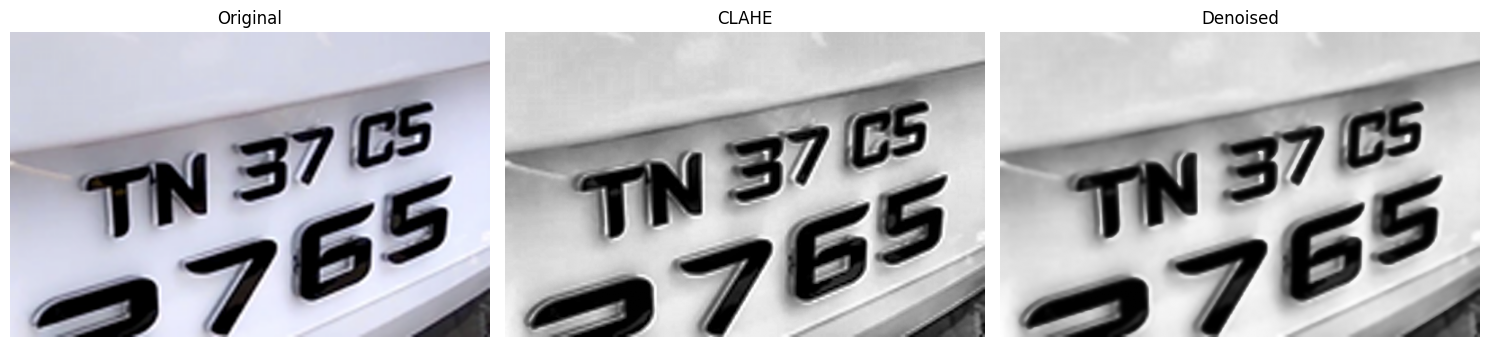

In [22]:
# ============================================
# STEP 19: IMPROVED LICENSE PLATE RECOGNITION
# ============================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

TEST_DIR = BASE / "prepared_yolo" / "test" / "images"

# Use the same test image
image_path = TEST_DIR / "Cars10.png"

image = cv2.imread(str(image_path))
assert image is not None, "Image not found"

# Detect plates at a higher input resolution
results = detector.predict(
    source=image,
    conf=0.30,
    iou=0.40,
    imgsz=640,
    verbose=False
)[0]

print("Image:", image_path.name)
print("Detected plate regions:", len(results.boxes))

H, W = image.shape[:2]

for index, box in enumerate(results.boxes):

    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    # Padding proportional to detected plate dimensions
    box_w = x2 - x1
    box_h = y2 - y1

    pad_x = int(box_w * 0.08)
    pad_y = int(box_h * 0.15)

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(W, x2 + pad_x)
    y2 = min(H, y2 + pad_y)

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        continue

    # Method 1: Original enlarged plate
    original = cv2.resize(
        crop, None, fx=3, fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # Method 2: Grayscale + CLAHE
    gray = cv2.cvtColor(
        original, cv2.COLOR_BGR2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    # Method 3: Bilateral filtering
    denoised = cv2.bilateralFilter(
        enhanced, 7, 50, 50
    )

    methods = {
        "Original": original,
        "CLAHE": enhanced,
        "Denoised": denoised
    }

    print(f"\n===== PLATE {index + 1} =====")
    print("Detection confidence:", round(float(box.conf[0]), 3))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for j, (method_name, processed) in enumerate(methods.items()):

        ocr_results = reader.readtext(
            processed,
            detail=1,
            paragraph=False
        )

        recognized_text = " ".join(
            result[1] for result in ocr_results
        )

        confidence = (
            np.mean([result[2] for result in ocr_results])
            if ocr_results else 0.0
        )

        print(
            f"{method_name}: {recognized_text} "
            f"(OCR confidence: {confidence:.3f})"
        )

        if len(processed.shape) == 2:
            axes[j].imshow(processed, cmap="gray")
        else:
            axes[j].imshow(
                cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
            )

        axes[j].set_title(method_name)
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

# Step 20 — Test OCR on multiple images

In [23]:
# ==========================================
# STEP 20: BATCH LICENSE PLATE OCR TESTING
# ==========================================

import cv2
import numpy as np
import pandas as pd
from pathlib import Path

TEST_DIR = BASE / "prepared_yolo" / "test" / "images"

# Test the first 20 images
test_images = sorted(TEST_DIR.glob("*.png"))[:20]

ocr_records = []

for image_path in test_images:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    height, width = image.shape[:2]

    # Detect plates
    predictions = detector.predict(
        source=image,
        conf=0.30,
        iou=0.40,
        imgsz=640,
        verbose=False
    )[0]

    if len(predictions.boxes) == 0:
        ocr_records.append({
            "image": image_path.name,
            "plate_index": None,
            "detected": False,
            "plate_text": "",
            "ocr_confidence": 0.0
        })
        continue

    # Process every detected plate separately
    for plate_index, box in enumerate(predictions.boxes):

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        pad_x = int((x2 - x1) * 0.08)
        pad_y = int((y2 - y1) * 0.15)

        x1 = max(0, x1 - pad_x)
        y1 = max(0, y1 - pad_y)
        x2 = min(width, x2 + pad_x)
        y2 = min(height, y2 + pad_y)

        crop = image[y1:y2, x1:x2]

        if crop.size == 0:
            continue

        enlarged = cv2.resize(
            crop,
            None,
            fx=3,
            fy=3,
            interpolation=cv2.INTER_CUBIC
        )

        # OCR on original enlarged crop
        ocr_results = reader.readtext(
            enlarged,
            detail=1,
            paragraph=False
        )

        recognized_text = " ".join(
            result[1] for result in ocr_results
        )

        ocr_confidence = (
            float(np.mean([result[2] for result in ocr_results]))
            if ocr_results else 0.0
        )

        ocr_records.append({
            "image": image_path.name,
            "plate_index": plate_index + 1,
            "detected": True,
            "plate_text": recognized_text,
            "detection_confidence": float(box.conf[0]),
            "ocr_confidence": ocr_confidence
        })

# Create results table
ocr_df = pd.DataFrame(ocr_records)

display(ocr_df)

# Save results to Google Drive
OUTPUT_DIR = BASE / "ocr_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_csv = OUTPUT_DIR / "batch_ocr_results.csv"

ocr_df.to_csv(output_csv, index=False)

print("OCR testing completed!")
print("Images tested:", len(test_images))
print("Results saved:", output_csv)

,image,plate_index,detected,plate_text,detection_confidence,ocr_confidence
0,Cars10.png,1.0,True,TN 37 Cs 7765,0.796631,0.832175
1,Cars106.png,1.0,True,,0.660855,0.000000
2,Cars106.png,2.0,True,,0.615541,0.000000
3,Cars106.png,3.0,True,,0.598601,0.000000
4,Cars129.png,1.0,True,VRGINIA OPEC Loi,0.770255,0.602790
5,Cars132.png,1.0,True,,0.687665,0.000000
6,Cars132.png,2.0,True,,0.343120,0.000000
7,Cars137.png,1.0,True,,0.592496,0.000000
8,Cars146.png,1.0,True,,0.501156,0.000000
9,Cars146.png,2.0,True,,0.495833,0.000000


OCR testing completed!
Images tested: 20
Results saved: /content/drive/MyDrive/Component02_Research/ocr_results/batch_ocr_results.csv


# Step 21 — Analyze OCR success and failure

========== OCR BASELINE RESULTS ==========
Total images tested: 20
Total plate detections: 29
Detections with OCR text: 14
Images with OCR text: 13
OCR text-return rate: 48.28%

========== OCR FAILURE CASES ==========


,image,detected,detection_confidence,ocr_confidence
1,Cars106.png,True,0.660855,0.0
2,Cars106.png,True,0.615541,0.0
3,Cars106.png,True,0.598601,0.0
5,Cars132.png,True,0.687665,0.0
6,Cars132.png,True,0.343120,0.0
7,Cars137.png,True,0.592496,0.0
8,Cars146.png,True,0.501156,0.0
9,Cars146.png,True,0.495833,0.0
10,Cars146.png,True,0.365067,0.0
13,Cars16.png,True,0.638586,0.0


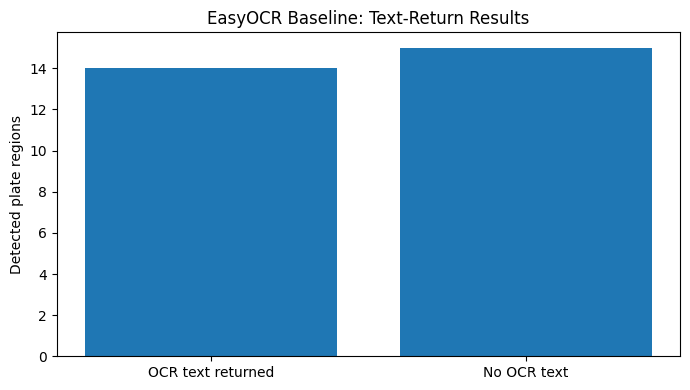

In [24]:
# ============================================
# STEP 21: OCR BASELINE ANALYSIS
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# Load the results generated in Step 20
ocr_df = pd.read_csv(
    BASE / "ocr_results" / "batch_ocr_results.csv"
)

# A nonempty OCR prediction does not necessarily
# mean the registration number is correct.
ocr_df["has_text"] = (
    ocr_df["plate_text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

total_images = ocr_df["image"].nunique()
total_detections = int(ocr_df["detected"].sum())
text_predictions = int(ocr_df["has_text"].sum())

# Count images containing at least one OCR prediction
images_with_text = ocr_df.groupby("image")["has_text"].any().sum()

print("========== OCR BASELINE RESULTS ==========")
print("Total images tested:", total_images)
print("Total plate detections:", total_detections)
print("Detections with OCR text:", text_predictions)
print("Images with OCR text:", images_with_text)

if total_detections:
    text_return_rate = text_predictions / total_detections * 100
    print(f"OCR text-return rate: {text_return_rate:.2f}%")

print("\n========== OCR FAILURE CASES ==========")

failed = ocr_df[
    (~ocr_df["has_text"]) |
    (~ocr_df["detected"])
]

display(
    failed[
        ["image", "detected", "detection_confidence",
         "ocr_confidence"]
    ]
)

# Plot number of regions with and without OCR output
plt.figure(figsize=(7, 4))

plt.bar(
    ["OCR text returned", "No OCR text"],
    [
        text_predictions,
        total_detections - text_predictions
    ]
)

plt.title("EasyOCR Baseline: Text-Return Results")
plt.ylabel("Detected plate regions")
plt.tight_layout()
plt.show()

# Step 22 — Improve OCR using multiple preprocessing methods

In [25]:
# ==========================================
# STEP 22: MULTI-PREPROCESSING OCR COMPARISON
# ==========================================

import cv2
import numpy as np
import pandas as pd
import re
from pathlib import Path

TEST_DIR = BASE / "prepared_yolo" / "test" / "images"

# Use the same first 20 images as Step 20
test_images = sorted(TEST_DIR.glob("*.png"))[:20]

records = []

def create_preprocessing_versions(crop):

    enlarged = cv2.resize(
        crop, None,
        fx=3, fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    gray = cv2.cvtColor(
        enlarged, cv2.COLOR_BGR2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    ).apply(gray)

    threshold = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31,
        11
    )

    denoised = cv2.bilateralFilter(
        gray, 7, 50, 50
    )

    return {
        "Original": enlarged,
        "CLAHE": clahe,
        "Adaptive": threshold,
        "Denoised": denoised
    }


def normalize_plate_text(text):
    return re.sub(
        r"[^A-Z0-9]",
        "",
        text.upper()
    )


for image_path in test_images:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    H, W = image.shape[:2]

    predictions = detector.predict(
        source=image,
        conf=0.30,
        iou=0.40,
        imgsz=640,
        verbose=False
    )[0]

    if len(predictions.boxes) == 0:
        continue

    for plate_index, box in enumerate(predictions.boxes):

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        pad_x = int((x2 - x1) * 0.08)
        pad_y = int((y2 - y1) * 0.15)

        x1 = max(0, x1 - pad_x)
        y1 = max(0, y1 - pad_y)
        x2 = min(W, x2 + pad_x)
        y2 = min(H, y2 + pad_y)

        crop = image[y1:y2, x1:x2]

        if crop.size == 0:
            continue

        variants = create_preprocessing_versions(crop)

        for method_name, processed in variants.items():

            ocr_results = reader.readtext(
                processed,
                detail=1,
                paragraph=False
            )

            text = " ".join(
                item[1] for item in ocr_results
            )

            confidence = (
                float(np.mean(
                    [item[2] for item in ocr_results]
                ))
                if ocr_results else 0.0
            )

            records.append({
                "image": image_path.name,
                "plate_index": plate_index + 1,
                "method": method_name,
                "recognized_text": text,
                "normalized_text": normalize_plate_text(text),
                "ocr_confidence": confidence,
                "has_text": bool(normalize_plate_text(text))
            })

comparison_ocr_df = pd.DataFrame(records)

display(comparison_ocr_df.head(20))

OUTPUT_DIR = BASE / "ocr_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

comparison_ocr_df.to_csv(
    OUTPUT_DIR / "preprocessing_comparison.csv",
    index=False
)

print("Preprocessing comparison completed!")

,image,plate_index,method,recognized_text,normalized_text,ocr_confidence,has_text
0,Cars10.png,1,Original,TN 37 Cs 7765,TN37CS7765,0.832175,True
1,Cars10.png,1,CLAHE,TN 37 Cs 7765,TN37CS7765,0.610290,True
2,Cars10.png,1,Adaptive,(C5 'TTIN 37 7665,C5TTIN377665,0.650693,True
3,Cars10.png,1,Denoised,TN 37 Cs 7765,TN37CS7765,0.929337,True
4,Cars106.png,1,Original,,,0.000000,False
5,Cars106.png,1,CLAHE,,,0.000000,False
6,Cars106.png,1,Adaptive,,,0.000000,False
7,Cars106.png,1,Denoised,,,0.000000,False
8,Cars106.png,2,Original,,,0.000000,False
9,Cars106.png,2,CLAHE,,,0.000000,False


Preprocessing comparison completed!


# Step 23 — Compare preprocessing methods

In [26]:
# ==========================================
# STEP 23: COMPARE OCR TEXT-RETURN RATES
# ==========================================

summary = (
    comparison_ocr_df
    .groupby("method")
    .agg(
        total_observations=("has_text", "size"),
        text_returned=("has_text", "sum"),
        average_confidence=("ocr_confidence", "mean")
    )
    .reset_index()
)

summary["text_return_rate"] = (
    summary["text_returned"]
    / summary["total_observations"] * 100
)

summary = summary.sort_values(
    "text_return_rate",
    ascending=False
)

display(summary)

summary.to_csv(
    OUTPUT_DIR / "preprocessing_summary.csv",
    index=False
)

,method,total_observations,text_returned,average_confidence,text_return_rate
0,Adaptive,29,17,0.249660,58.620690
1,CLAHE,29,16,0.250054,55.172414
2,Denoised,29,14,0.246350,48.275862
3,Original,29,14,0.242084,48.275862


# Step 24 — Compare the text consistency between methods

In [28]:
# ============================================
# STEP 24: OCR CONSISTENCY ANALYSIS
# ============================================

import pandas as pd

# Load the preprocessing results
comparison_path = (
    BASE / "ocr_results"
    / "preprocessing_comparison.csv"
)

df = pd.read_csv(comparison_path)

# Replace missing OCR text with empty strings
df["normalized_text"] = (
    df["normalized_text"]
    .fillna("")
    .astype(str)
)

# Group OCR outputs belonging to the same
# detected plate in the same image.
consistency_records = []

for (image, plate_index), group in df.groupby(
    ["image", "plate_index"]
):

    # Consider only nonempty text predictions
    valid = group[
        group["normalized_text"].str.len() > 0
    ]

    if valid.empty:
        final_text = ""
        agreement = 0
        votes = 0

    else:
        # Choose the most frequently predicted text
        counts = valid["normalized_text"].value_counts()

        final_text = counts.index[0]
        votes = int(counts.iloc[0])

        # Agreement across all four preprocessing methods
        agreement = votes / len(group)

    consistency_records.append({
        "image": image,
        "plate_index": plate_index,
        "final_text": final_text,
        "matching_methods": votes,
        "agreement_ratio": agreement
    })

consistency_df = pd.DataFrame(consistency_records)

display(
    consistency_df.sort_values(
        "agreement_ratio",
        ascending=False
    )
)

# Save results
consistency_df.to_csv(
    BASE / "ocr_results"
    / "ocr_consistency.csv",
    index=False
)

print("OCR consistency analysis completed!")

,image,plate_index,final_text,matching_methods,agreement_ratio
16,Cars183.png,1,BRIT0001,4,1.00
21,Cars27.png,1,DZI7YXR,3,0.75
23,Cars277.png,1,AALAMYSTOCKPHOTO,3,0.75
0,Cars10.png,1,TN37CS7765,3,0.75
18,Cars240.png,1,4CDAF,2,0.50
22,Cars271.png,1,YESBOSS,2,0.50
28,Cars287.png,1,DL7CN5617,2,0.50
25,Cars277.png,3,AMFREX,2,0.50
12,Cars151.png,1,DL3C3D6082,1,0.25
4,Cars129.png,1,VRGINIAOPECLOI,1,0.25


OCR consistency analysis completed!


Important findings
Finding 1: OCR preprocessing consistency is working. The results demonstrate that your system can compare multiple OCR outputs and identify repeated predictions.

Finding 2: Agreement does not guarantee accuracy. For example, AALAMYSTOCKPHOTO has 75% agreement but appears to be text unrelated to a license plate.

Finding 3: Some plates remain unreadable. Several observations have 0% agreement because all four preprocessing methods returned empty text.